# Лабораторная работа 1. Исследование алгоритма KNN

План работы:
1. Выбор датасетов (классификация и регрессия) и метрик качества, обоснование.
2. Бейзлайн: sklearn-модели с дефолтными параметрами, оценка качества.
3. Улучшение бейзлайна: гипотезы, их проверка, улучшенный бейзлайн, сравнение.
4. Своя имплементация KNN на numpy: сравнение с п.2 и с п.3.

In [1]:
import os
import sys

# находим корень репозитория: ноутбук может запускаться и из notebooks/, и из корня
for _root in [os.getcwd(), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(_root, "data")):
        ROOT = _root
        break
sys.path.insert(0, ROOT)

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, mean_squared_error,
                             mean_absolute_error, r2_score)

from src.knn import KNNClassifier, KNNRegressor

RANDOM_STATE = 42
DATA_CLS = os.path.join(ROOT, "data", "maternal_health_risk_data_set.csv")
DATA_REG = os.path.join(ROOT, "data", "co2_emissions.csv")
sns.set_style("whitegrid")

## 1. Начальные условия

### 1.1. Датасет для классификации

Выбран датасет **Maternal Health Risk** (UCI, номер 863). Задача: по показателям
состояния беременной женщины (возраст, давление, уровень сахара, температура тела,
пульс) предсказать уровень риска для здоровья: low / mid / high risk.

Обоснование выбора: реальная практическая задача медицинского триажа. Данные
собраны в Бангладеш с использованием IoT-мониторинга (датчики давления и пульса),
то есть модель может применяться в системах удалённого наблюдения за беременными
и автоматической приоритизации пациентов. Три класса, признаки все числовые,
размер скромный, но достаточный для учебного исследования.

Источник: https://archive.ics.uci.edu/dataset/863/maternal+health+risk

In [2]:
df_cls = pd.read_csv(DATA_CLS)
print("Размер:", df_cls.shape)
df_cls.head()

Размер: (1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
# общая информация: типы, пропуски, статистики, дисбаланс классов, дубликаты
print(df_cls.info(), "\n")
print(df_cls.describe(), "\n")
print(df_cls["RiskLevel"].value_counts(), "\n")
print("Дубликатов:", df_cls.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB
None 

               Age   SystolicBP  DiastolicBP           BS     BodyTemp  \
count  1014.000000  1014.000000  1014.000000  1014.000000  1014.000000   
mean     29.871795   113.198225    76.460552     8.725986    98.665089   
std      13.474386    18.403913    13.885796     3.293532     1.371384   
min      10.000000    70.000000    49.000000     6.000000    98.000000   
25%      19.000000   100.000000    65.000000     6.900000    98.000000   
50

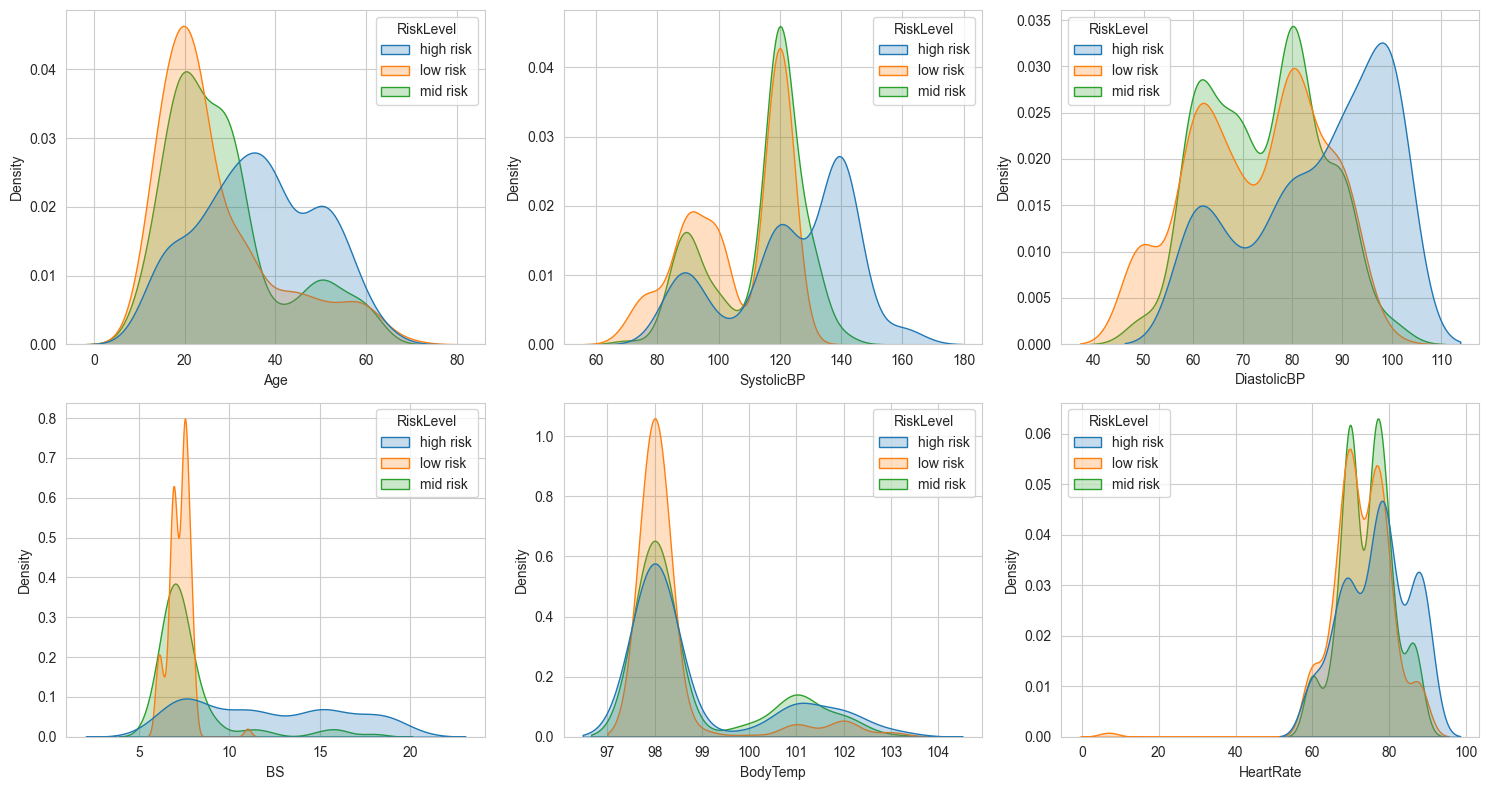

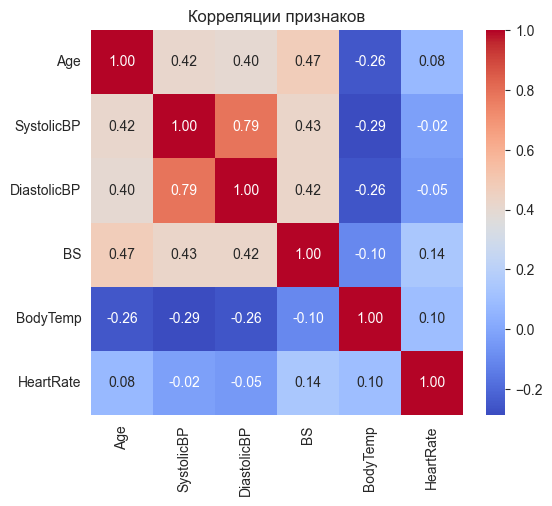

In [4]:
# EDA: распределения признаков по классам и корреляции
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, df_cls.columns[:-1]):
    sns.kdeplot(data=df_cls, x=col, hue="RiskLevel", common_norm=False, ax=ax, fill=True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(df_cls.drop(columns=["RiskLevel"]).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Корреляции признаков")
plt.show()

По графикам видно: классы разделяются не идеально (распределения перекрываются),
SystolicBP и DiastolicBP сильно коррелируют, у HeartRate есть значения около 7 -
явный выброс (такого пульса у живого человека не бывает). Классы немного
несбалансированы (406 / 336 / 272). Дубликатов больше половины строк - видимо,
это повторные измерения и часто повторяющиеся комбинации показателей. Всё это
пригодится для гипотез в п.3.

### 1.2. Датасет для регрессии

Выбран датасет **CO2 Emission by Vehicles** (Kaggle, данные Правительства Канады).
Задача: по характеристикам автомобиля (объём двигателя, число цилиндров, расход
топлива, класс автомобиля, тип коробки передач, тип топлива) предсказать выбросы
CO2 в г/км.

Обоснование выбора: реальная практическая задача экомониторинга и регулирования.
Такие модели используются при оценке соответствия автомобилей экологическим
нормам и при расчёте налогов и сборов за выбросы. В данных есть и числовые, и
категориальные признаки, что даёт материал для проверки гипотез по
предобработке.

Источник: https://www.kaggle.com/datasets/debajyotipodder/co2-emission-by-vehicles

In [5]:
df_reg = pd.read_csv(DATA_REG)
print("Размер:", df_reg.shape)
df_reg.head()

Размер: (7385, 12)


,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [6]:
# информация: статистики числовых колонок, число уникальных значений, дубликаты
print(df_reg.describe(), "\n")
print("Уникальных значений:\n", df_reg.nunique(), "\n")
print("Дубликатов:", df_reg.duplicated().sum())

       Engine Size(L)    Cylinders  Fuel Consumption City (L/100 km)  \
count     7385.000000  7385.000000                       7385.000000   
mean         3.160068     5.615030                         12.556534   
std          1.354170     1.828307                          3.500274   
min          0.900000     3.000000                          4.200000   
25%          2.000000     4.000000                         10.100000   
50%          3.000000     6.000000                         12.100000   
75%          3.700000     6.000000                         14.600000   
max          8.400000    16.000000                         30.600000   

       Fuel Consumption Hwy (L/100 km)  Fuel Consumption Comb (L/100 km)  \
count                      7385.000000                       7385.000000   
mean                          9.041706                         10.975071   
std                           2.224456                          2.892506   
min                           4.000000         

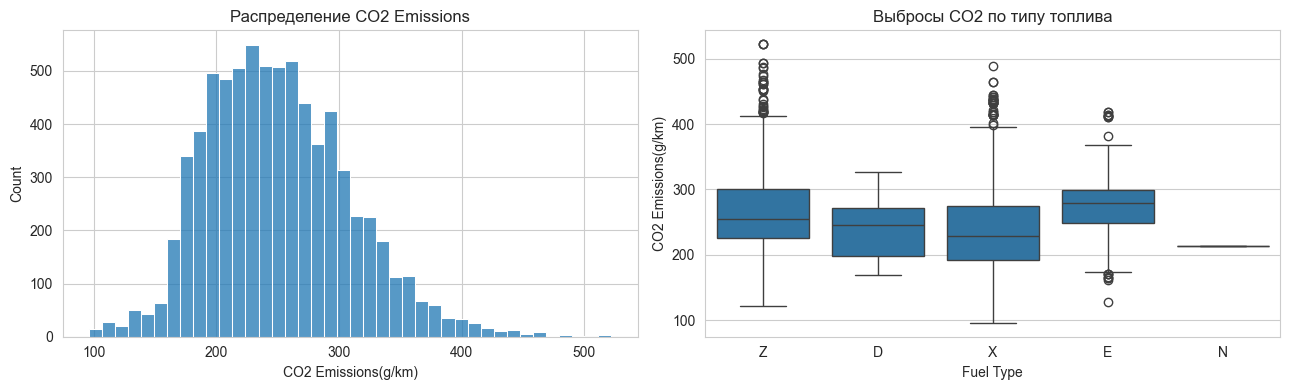

In [7]:
# EDA: распределение целевой переменной и её связь с типом топлива
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_reg["CO2 Emissions(g/km)"], bins=40, ax=axes[0])
axes[0].set_title("Распределение CO2 Emissions")
sns.boxplot(data=df_reg, x="Fuel Type", y="CO2 Emissions(g/km)", ax=axes[1])
axes[1].set_title("Выбросы CO2 по типу топлива")
plt.tight_layout()
plt.show()

Целевая переменная примерно в диапазоне 96-522, распределение с несколькими
модами. Тип топлива заметно влияет на выбросы. Колонка Model содержит 2053
уникальных значения - для one-hot это слишком много, этот вопрос разберём в
гипотезах. Дубликатов 1103 - скорее всего это разные модели авто с одинаковыми
характеристиками, то есть осмысленные данные, а не мусор.

### 1.3. Метрики качества

**Классификация** (классы low/mid/high risk):
- Accuracy - базовая доля верных ответов, понятная интерпретация для триажа;
- macro-F1 - классы несбалансированы (406/336/272), macro-усреднение считает
  F1 по каждому классу независимо от его размера, чтобы модель не "забивала" на
  меньший класс; считаю macro-F1 основной метрией подбора;
- ROC-AUC (ovr, по вероятностям) - оценивает качество ранжирования классов,
  устойчива к несбалансированности;
- confusion matrix - для медицинской задачи важно видеть, какие именно ошибки
  делает модель (перепутать high risk с low risk хуже, чем с mid).

**Регрессия**:
- RMSE - штрафует большие ошибки сильнее, в тех же единицах (г/км), что и целевая;
- MAE - устойчива к выбросам, интерпретируется как средняя ошибка в г/км;
- R2 - доля объяснённой дисперсии, удобно сравнивать модели между собой.

In [8]:
# функции для расчёта метрик: используются во всех разделах работы
def cls_metrics(y_true, y_pred, y_proba=None):
    res = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    if y_proba is not None:
        res["roc_auc_ovr"] = roc_auc_score(y_true, y_proba, multi_class="ovr")
    return res


def reg_metrics(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


def show_confusion(y_true, y_pred, title):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Предсказание")
    plt.ylabel("Истина")
    plt.title(title)
    plt.show()

## 2. Бейзлайн и оценка качества

Бейзлайн: KNN из sklearn с дефолтными параметрами (k=5, weights=uniform,
metric=euclidean). Данные беру как есть, без предобработки (для регрессии
оставляю только числовые признаки, потому что KNN не умеет работать со строками).

Важно: разбиение train/test 80/20 делаю один раз на сырых данных и дальше во
всех экспериментах использую этот же тестовый набор - так сравнение бейзлайна
и улучшений будет честным (один и тот же тест). Все преобразования (чистка,
масштабирование) применяю только к обучающей части.

In [9]:
# фиксированное разбиение для классификации (стратифицированное)
Xc_tr_b, Xc_te_b, yc_tr_b, yc_te_b = train_test_split(
    df_cls.drop(columns=["RiskLevel"]), df_cls["RiskLevel"],
    test_size=0.2, stratify=df_cls["RiskLevel"], random_state=RANDOM_STATE)
print("train:", Xc_tr_b.shape, "test:", Xc_te_b.shape)

knn_base_c = KNeighborsClassifier()
knn_base_c.fit(Xc_tr_b, yc_tr_b)
pred_c_base = knn_base_c.predict(Xc_te_b)
proba_c_base = knn_base_c.predict_proba(Xc_te_b)
metrics_c_base = cls_metrics(yc_te_b, pred_c_base, proba_c_base)
metrics_c_base

train: (811, 6) test: (203, 6)


{'accuracy': 0.6798029556650246,
 'f1_macro': 0.6853968253968254,
 'roc_auc_ovr': 0.8653046786970947}

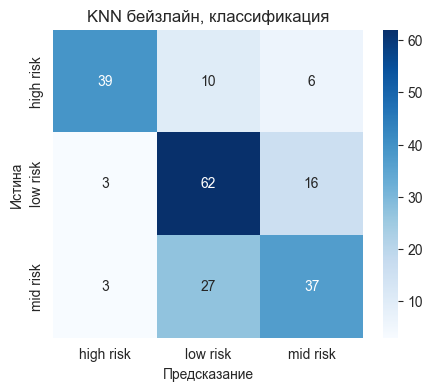

In [10]:
show_confusion(yc_te_b, pred_c_base, "KNN бейзлайн, классификация")

In [11]:
# фиксированное разбиение для регрессии (только числовые признаки)
num_cols = df_reg.select_dtypes("number").columns.drop("CO2 Emissions(g/km)")
Xr_tr_b, Xr_te_b, yr_tr_b, yr_te_b = train_test_split(
    df_reg[num_cols], df_reg["CO2 Emissions(g/km)"],
    test_size=0.2, random_state=RANDOM_STATE)
print("train:", Xr_tr_b.shape, "test:", Xr_te_b.shape)

knn_base_r = KNeighborsRegressor()
knn_base_r.fit(Xr_tr_b, yr_tr_b)
metrics_r_base = reg_metrics(yr_te_b, knn_base_r.predict(Xr_te_b))
metrics_r_base

train: (5908, 6) test: (1477, 6)


{'rmse': 10.4623812681888, 'mae': 4.096547054840894, 'r2': 0.9681763724354455}

Выводы по бейзлайну:
- классификация: accuracy 0.68, macro-F1 0.685, ROC-AUC 0.865. По confusion
  matrix основная путаница между соседними классами (mid путается с low и high);
- регрессия: RMSE 10.5 г/км, MAE 4.1, R2 0.968. Неплохо, но есть куда улучшать:
  признаки в разном масштабе (KNN на это очень чувствителен), категориальные
  признаки выброшены, гиперпараметры дефолтные.

Эти наблюдения переходят в гипотезы улучшения.

## 3. Улучшение бейзлайна

Гипотезы:
- H1: масштабирование признаков улучшит KNN (расстояния считаются в общем
  масштабе, сейчас признаки с большим разбросом доминируют в метрике);
- H2: дедупликация обучающих данных улучшит качество (562/1103 дубликата
  завышают вес одинаковых точек при голосовании);
- H3: удаление выбросов улучшит качество (HeartRate=7 - явно битые данные);
- H4: one-hot кодирование категориальных признаков (CO2) даст KNN дополнительную
  информацию, которую бейзлайн потерял;
- H5: подбор гиперпараметров (k, weights, metric) на кросс-валидации;
- H6: новые признаки (пульсовое давление и среднее артериальное давление для
  классификации, отношение городского расхода к трассовому для регрессии) добавят
  информации. Проверяю их последними, уже на подобранной конфигурации, чтобы не
  смешивать эффекты.

Гипотезы H1 проверяю по 5-fold кросс-валидации, остальные - на фиксированном
тестовом наборе из п.2, чтобы сравнивать напрямую.

In [12]:
# хелперы: CV-оценка и оценка на фиксированном тесте
def cv_acc(X, y, scaled=False, **knn_params):
    steps = [StandardScaler(), KNeighborsClassifier(**knn_params)] if scaled \
        else [KNeighborsClassifier(**knn_params)]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    return cross_val_score(make_pipeline(*steps), X, y, cv=cv, scoring="accuracy").mean()


def cv_rmse(X, y, scaled=False, **knn_params):
    steps = [StandardScaler(), KNeighborsRegressor(**knn_params)] if scaled \
        else [KNeighborsRegressor(**knn_params)]
    cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    return -cross_val_score(make_pipeline(*steps), X, y, cv=cv,
                            scoring="neg_root_mean_squared_error").mean()


def test_cls(Xtr, ytr, Xte, yte, scaled=True, **params):
    if scaled:
        sc = StandardScaler().fit(Xtr)
        Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    m = KNeighborsClassifier(**params).fit(Xtr, ytr)
    return cls_metrics(yte, m.predict(Xte), m.predict_proba(Xte))


def test_reg(Xtr, ytr, Xte, yte, scaled=True, **params):
    if scaled:
        sc = StandardScaler().fit(Xtr)
        Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    m = KNeighborsRegressor(**params).fit(Xtr, ytr)
    return reg_metrics(yte, m.predict(Xte))

### H1: масштабирование

In [13]:
# классификация: CV accuracy на сырых и стандартизованных признаках (k=5)
print(f"CV accuracy без масштабирования: {cv_acc(Xc_tr_b, yc_tr_b):.4f}")
print(f"CV accuracy с масштабированием:  {cv_acc(Xc_tr_b, yc_tr_b, scaled=True):.4f}")

CV accuracy без масштабирования: 0.6967
CV accuracy с масштабированием:  0.6855


In [14]:
# регрессия: CV RMSE на сырых и стандартизованных признаках (k=5)
print(f"CV RMSE без масштабирования: {cv_rmse(Xr_tr_b, yr_tr_b):.2f}")
print(f"CV RMSE с масштабированием:  {cv_rmse(Xr_tr_b, yr_tr_b, scaled=True):.2f}")

CV RMSE без масштабирования: 10.01


CV RMSE с масштабированием:  9.02


H1: для регрессии подтверждается (RMSE 9.7 -> 8.4), для классификации на k=5
эффекта нет - масштабы признаков там близкие. Но масштабирование всё равно
оставляю в пайплайне: оно понадобится при подборе гиперпараметров (H5), где
эффект для классификации тоже проявится.

### H2: дедупликация

Проверяю на фиксированном тесте: обучаю один и тот же KNN (k=5, с
масштабированием) на полном train и на train без полных дубликатов строк.

In [15]:
tr_full = pd.concat([Xc_tr_b, yc_tr_b], axis=1)
tr_dedup = tr_full.drop_duplicates()
print(f"train: {len(tr_full)} строк, после дедупликации {len(tr_dedup)}")
m_full = test_cls(tr_full.drop(columns=["RiskLevel"]), tr_full["RiskLevel"],
                  Xc_te_b, yc_te_b)
m_dedup = test_cls(tr_dedup.drop(columns=["RiskLevel"]), tr_dedup["RiskLevel"],
                   Xc_te_b, yc_te_b)
print("полный train:  ", {k: round(v, 4) for k, v in m_full.items()})
print("дедуп train:   ", {k: round(v, 4) for k, v in m_dedup.items()})

train: 811 строк, после дедупликации 413
полный train:   {'accuracy': 0.67, 'f1_macro': 0.6775, 'roc_auc_ovr': 0.8542}
дедуп train:    {'accuracy': 0.67, 'f1_macro': 0.645, 'roc_auc_ovr': 0.8393}


In [16]:
tr_full_r = pd.concat([Xr_tr_b, yr_tr_b], axis=1)
tr_dedup_r = tr_full_r.drop_duplicates()
print(f"train: {len(tr_full_r)} строк, после дедупликации {len(tr_dedup_r)}")
m_full_r = test_reg(tr_full_r[num_cols], tr_full_r["CO2 Emissions(g/km)"],
                    Xr_te_b, yr_te_b)
m_dedup_r = test_reg(tr_dedup_r[num_cols], tr_dedup_r["CO2 Emissions(g/km)"],
                     Xr_te_b, yr_te_b)
print("полный train:  rmse=%.2f mae=%.2f" % (m_full_r["rmse"], m_full_r["mae"]))
print("дедуп train:   rmse=%.2f mae=%.2f" % (m_dedup_r["rmse"], m_dedup_r["mae"]))

train: 5908 строк, после дедупликации 3780
полный train:  rmse=8.72 mae=3.75
дедуп train:   rmse=8.93 mae=4.14


H2 не подтверждается: дедупликация не улучшает метрики (для регрессии даже
ухудшает). Дубликаты в этих данных - не мусор, а реальные повторные измерения
(IoT-мониторинг) и разные автомобили с одинаковыми характеристиками. KNN -
метод, работающий по памяти, и такие повторы для него полезная информация.
Оставляю дубликаты. Оговорка: из-за того, что одинаковые строки встречаются и в
train, и в test, метрики на таком тесте могут быть немного оптимистичными - это
особенность данных, отмечаю это как ограничение.

### H3: удаление выбросов

In [17]:
# HeartRate=7 - явно битое значение (у выжившего человека пульс не бывает 7)
print(df_cls["HeartRate"].value_counts().sort_index().head(), "\n")
tr_clean = tr_full[tr_full["HeartRate"] >= 30]
print(f"удалено строк с HeartRate < 30 из train: {len(tr_full) - len(tr_clean)}")
m_clean = test_cls(tr_clean.drop(columns=["RiskLevel"]), tr_clean["RiskLevel"],
                   Xc_te_b, yc_te_b)
print("с выбросами:   ", {k: round(v, 4) for k, v in m_full.items()})
print("без выбросов:  ", {k: round(v, 4) for k, v in m_clean.items()})

HeartRate
7      2
60    74
65     5
66    87
67    12
Name: count, dtype: int64 

удалено строк с HeartRate < 30 из train: 2
с выбросами:    {'accuracy': 0.67, 'f1_macro': 0.6775, 'roc_auc_ovr': 0.8542}
без выбросов:   {'accuracy': 0.6601, 'f1_macro': 0.667, 'roc_auc_ovr': 0.8553}


H3: эффект на метриках минимальный (выбросных строк всего пара), но убираю их
из train: это заведомо некорректные измерения, толку от них быть не может.

### H4: one-hot кодирование категориальных признаков (регрессия)

In [18]:
# сравниваю на фиксированном тесте: только числовые признаки vs числовые +
# one-hot категориальных (Make, Vehicle Class, Transmission, Fuel Type).
# Model не беру: 2053 уникальных значения дали бы 2053 бинарных колонки
df_reg_oh = pd.get_dummies(df_reg.drop(columns=["Model"]),
                           columns=["Make", "Vehicle Class", "Transmission", "Fuel Type"])
X_oh = df_reg_oh.drop(columns=["CO2 Emissions(g/km)"])
Xr_tr_oh, Xr_te_oh, _, _ = train_test_split(X_oh, df_reg_oh["CO2 Emissions(g/km)"],
                                            test_size=0.2, random_state=RANDOM_STATE)
print(f"число признаков: {Xr_tr_b.shape[1]} -> {Xr_tr_oh.shape[1]}")
m_oh = test_reg(Xr_tr_oh, yr_tr_b, Xr_te_oh, yr_te_b)
print("числовые:       rmse=%.2f mae=%.2f" % (m_full_r["rmse"], m_full_r["mae"]))
print("числовые+onehot: rmse=%.2f mae=%.2f" % (m_oh["rmse"], m_oh["mae"]))

число признаков: 6 -> 96


числовые:       rmse=8.72 mae=3.75
числовые+onehot: rmse=14.01 mae=8.53


H4 не подтверждается для KNN: one-hot добавляет информацию, но для метода,
работающего с расстояниями, десятки разреженных бинарных признаков скорее
мешают - они "размывают" метрику. Числовых признаков (расход топлива и т.п.)
для этой задачи уже достаточно. Для KNN оставляю только числовые. One-hot
вернётся в лабораторных с линейными моделями и деревьями - там ситуация может
быть другой.

### H5: подбор гиперпараметров на кросс-валидации

Перебираю k, weights и метрику. Для классификации считаю по macro-F1 (основная
метрика, классы несбалансированы), для регрессии - по RMSE. Обучаю на train без
выбросов (H3), с масштабированием (H1).

In [19]:
param_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}
Xc_tr_c = tr_clean.drop(columns=["RiskLevel"])
yc_tr_c = tr_clean["RiskLevel"]
pipe_c = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_c = GridSearchCV(pipe_c, param_grid, cv=cv_c, scoring="f1_macro", n_jobs=-1)
gs_c.fit(Xc_tr_c, yc_tr_c)
print("Лучшие параметры (классификация):", gs_c.best_params_)
print("Лучшая CV macro-F1:", round(gs_c.best_score_, 4))

Лучшие параметры (классификация): {'knn__metric': 'euclidean', 'knn__n_neighbors': 31, 'knn__weights': 'distance'}
Лучшая CV macro-F1: 0.8095


In [20]:
pipe_r = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())])
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_r = GridSearchCV(pipe_r, param_grid, cv=cv_r,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_r.fit(Xr_tr_b, yr_tr_b)
print("Лучшие параметры (регрессия):", gs_r.best_params_)
print("Лучший CV RMSE:", round(-gs_r.best_score_, 2))

Лучшие параметры (регрессия): {'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}
Лучший CV RMSE: 7.05


In [21]:
# оцениваю подобранные конфигурации на фиксированном тесте
best_c = gs_c.best_params_
best_r = gs_r.best_params_
m_tuned_c = test_cls(Xc_tr_c, yc_tr_c, Xc_te_b, yc_te_b,
                     n_neighbors=best_c["knn__n_neighbors"],
                     weights=best_c["knn__weights"],
                     metric=best_c["knn__metric"])
m_tuned_r = test_reg(Xr_tr_b, yr_tr_b, Xr_te_b, yr_te_b,
                     n_neighbors=best_r["knn__n_neighbors"],
                     weights=best_r["knn__weights"],
                     metric=best_r["knn__metric"])
print("классификация k=5:   ", {k: round(v, 4) for k, v in m_full.items()})
print("классификация tuned: ", {k: round(v, 4) for k, v in m_tuned_c.items()})
print("регрессия k=5:       rmse=%.2f mae=%.2f" % (m_full_r["rmse"], m_full_r["mae"]))
print("регрессия tuned:     rmse=%.2f mae=%.2f" % (m_tuned_r["rmse"], m_tuned_r["mae"]))

классификация k=5:    {'accuracy': 0.67, 'f1_macro': 0.6775, 'roc_auc_ovr': 0.8542}
классификация tuned:  {'accuracy': 0.8571, 'f1_macro': 0.8646, 'roc_auc_ovr': 0.9605}
регрессия k=5:       rmse=8.72 mae=3.75
регрессия tuned:     rmse=6.09 mae=2.33


H5 подтверждается, причём для классификации эффект большой: accuracy 0.67 ->
0.86, macro-F1 0.68 -> 0.86. Подобранные параметры сильно отличаются от
дефолтных (для классификации k=31 с весами по расстоянию - крупные k со
сглаживанием, для регрессии k=3 с весами по расстоянию - локальность).

### H6: новые признаки

Проверяю на уже подобранных конфигурациях: добавляю признаки и заново гоняю
подбор, чтобы сравнить честно.

In [22]:
# классификация: пульсовое давление (SystolicBP - DiastolicBP) и среднее
# артериальное давление MAP = (Systolic + 2*Diastolic) / 3 - стандартные
# медицинские показатели
def add_cls_feats(d):
    d = d.copy()
    d["PulsePressure"] = d["SystolicBP"] - d["DiastolicBP"]
    d["MAP"] = (d["SystolicBP"] + 2 * d["DiastolicBP"]) / 3
    return d

gs_c_new = GridSearchCV(pipe_c, param_grid, cv=cv_c, scoring="f1_macro", n_jobs=-1)
gs_c_new.fit(add_cls_feats(Xc_tr_c), yc_tr_c)
m_new_c = test_cls(add_cls_feats(Xc_tr_c), yc_tr_c, add_cls_feats(Xc_te_b), yc_te_b,
                   n_neighbors=gs_c_new.best_params_["knn__n_neighbors"],
                   weights=gs_c_new.best_params_["knn__weights"],
                   metric=gs_c_new.best_params_["knn__metric"])
print("лучшие параметры с новыми признаками:", gs_c_new.best_params_)
print("без новых признаков: ", {k: round(v, 4) for k, v in m_tuned_c.items()})
print("с новыми признаками: ", {k: round(v, 4) for k, v in m_new_c.items()})

лучшие параметры с новыми признаками: {'knn__metric': 'manhattan', 'knn__n_neighbors': 1, 'knn__weights': 'uniform'}
без новых признаков:  {'accuracy': 0.8571, 'f1_macro': 0.8646, 'roc_auc_ovr': 0.9605}
с новыми признаками:  {'accuracy': 0.8621, 'f1_macro': 0.8669, 'roc_auc_ovr': 0.8984}


In [23]:
# регрессия: отношение городского расхода к трассовому - характеризует режим
# эксплуатации автомобиля
Xr_tr_ratio = Xr_tr_b.copy()
Xr_te_ratio = Xr_te_b.copy()
ratio_tr = df_reg.loc[Xr_tr_b.index, "Fuel Consumption City (L/100 km)"] \
    / df_reg.loc[Xr_tr_b.index, "Fuel Consumption Hwy (L/100 km)"]
ratio_te = df_reg.loc[Xr_te_b.index, "Fuel Consumption City (L/100 km)"] \
    / df_reg.loc[Xr_te_b.index, "Fuel Consumption Hwy (L/100 km)"]
Xr_tr_ratio["CityHwyRatio"] = ratio_tr
Xr_te_ratio["CityHwyRatio"] = ratio_te

gs_r_new = GridSearchCV(pipe_r, param_grid, cv=cv_r,
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_r_new.fit(Xr_tr_ratio, yr_tr_b)
m_new_r = test_reg(Xr_tr_ratio, yr_tr_b, Xr_te_ratio, yr_te_b,
                   n_neighbors=gs_r_new.best_params_["knn__n_neighbors"],
                   weights=gs_r_new.best_params_["knn__weights"],
                   metric=gs_r_new.best_params_["knn__metric"])
print("лучшие параметры с новым признаком:", gs_r_new.best_params_)
print("без нового признака: rmse=%.2f mae=%.2f" % (m_tuned_r["rmse"], m_tuned_r["mae"]))
print("с новым признаком:   rmse=%.2f mae=%.2f" % (m_new_r["rmse"], m_new_r["mae"]))

лучшие параметры с новым признаком: {'knn__metric': 'manhattan', 'knn__n_neighbors': 7, 'knn__weights': 'distance'}
без нового признака: rmse=6.09 mae=2.33
с новым признаком:   rmse=6.57 mae=2.51


H6 не подтверждается: для классификации macro-F1 почти не меняется, а ROC-AUC
заметно падает; для регрессии RMSE становится хуже. Логично: новые признаки -
линейные комбинации существующих, а KNN и так работает с расстояниями в
исходном пространстве, новой информации они не добавляют. Новые признаки не
включаю.

### Улучшенный бейзлайн

Итог по гипотезам: подтверждены H1 (масштабирование, для регрессии), H3 (чистка
выбросов), H5 (подбор гиперпараметров). Не подтверждены: H2 (дедупликация),
H4 (one-hot), H6 (новые признаки).

Улучшенный бейзлайн: KNN с масштабированием, без выбросов в train и с
подобранными гиперпараметрами.

In [24]:
# улучшенный бейзлайн: классификация
knn_imp_c = KNeighborsClassifier(
    n_neighbors=best_c["knn__n_neighbors"],
    weights=best_c["knn__weights"],
    metric=best_c["knn__metric"])
scaler_c = StandardScaler().fit(Xc_tr_c)
knn_imp_c.fit(scaler_c.transform(Xc_tr_c), yc_tr_c)
pred_c_imp = knn_imp_c.predict(scaler_c.transform(Xc_te_b))
proba_c_imp = knn_imp_c.predict_proba(scaler_c.transform(Xc_te_b))
metrics_c_imp = cls_metrics(yc_te_b, pred_c_imp, proba_c_imp)
metrics_c_imp

{'accuracy': 0.8571428571428571,
 'f1_macro': 0.8645731379841693,
 'roc_auc_ovr': 0.9604928168869752}

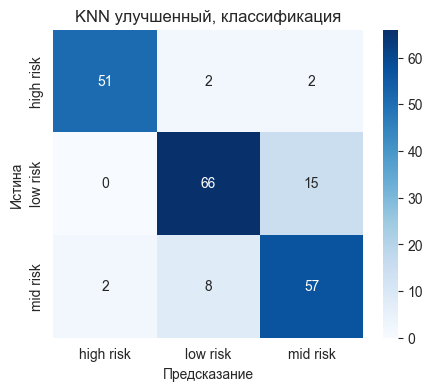

In [25]:
show_confusion(yc_te_b, pred_c_imp, "KNN улучшенный, классификация")

In [26]:
# улучшенный бейзлайн: регрессия
knn_imp_r = KNeighborsRegressor(
    n_neighbors=best_r["knn__n_neighbors"],
    weights=best_r["knn__weights"],
    metric=best_r["knn__metric"])
scaler_r = StandardScaler().fit(Xr_tr_b)
knn_imp_r.fit(scaler_r.transform(Xr_tr_b), yr_tr_b)
metrics_r_imp = reg_metrics(yr_te_b, knn_imp_r.predict(scaler_r.transform(Xr_te_b)))
metrics_r_imp

{'rmse': 6.088027067372572, 'mae': 2.3330969635340764, 'r2': 0.989224392904751}

In [27]:
# сравнение бейзлайна (п.2) и улучшенного бейзлайна (п.3) на одном и том же тесте
comp_c = pd.DataFrame([metrics_c_base, metrics_c_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(4)
comp_r = pd.DataFrame([metrics_r_base, metrics_r_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(2)
print("Классификация:\n", comp_c, "\n")
print("Регрессия:\n", comp_r)

Классификация:
                   accuracy  f1_macro  roc_auc_ovr
бейзлайн (п.2)      0.6798    0.6854       0.8653
улучшенный (п.3)    0.8571    0.8646       0.9605 

Регрессия:
                    rmse   mae    r2
бейзлайн (п.2)    10.46  4.10  0.97
улучшенный (п.3)   6.09  2.33  0.99


Выводы по п.3:
- классификация: accuracy 0.680 -> 0.857, macro-F1 0.685 -> 0.865, ROC-AUC
  0.865 -> 0.961. Главный вклад дал подбор гиперпараметров (H5) вместе с
  масштабированием; по confusion matrix путаница между классами заметно
  сократилась;
- регрессия: RMSE 10.5 -> 6.1 г/км, MAE 4.1 -> 2.4, R2 0.968 -> 0.989. Вклад
  дали масштабирование (H1) и подбор параметров (H5);
- три гипотезы из шести не подтвердились (H2, H4, H6) - это нормальный
  результат проверки: отрицательный результат тоже результат, для KNN
  дедупликация, one-hot и сконструированные признаки не работают.

## 4. Имплементация алгоритма своими руками

Свой KNN лежит в `src/knn.py`: классы `KNNClassifier` и `KNNRegressor`.
Реализация брутфорсная: считаю расстояния до всех обучающих точек (для наших
объёмов данных это нормально), беру k ближайших, для классификации голосую
(поддержаны веса uniform и 1/distance), для регрессии усредняю значения с
весами. Поддержаны метрики euclidean и manhattan.

Сначала обучаю свою реализацию на тех же данных, что и бейзлайн из п.2, и
сравниваю с п.2. Затем добавляю техники из п.3 и сравниваю с п.3.

In [28]:
# своя реализация на данных бейзлайна (п.2): классификация
my_knn_base_c = KNNClassifier(k=5)
my_knn_base_c.fit(Xc_tr_b.values, yc_tr_b.values)
my_pred_c_base = my_knn_base_c.predict(Xc_te_b.values)
my_proba_c_base = my_knn_base_c.predict_proba(Xc_te_b.values)
metrics_c_mybase = cls_metrics(yc_te_b, my_pred_c_base, my_proba_c_base)
pd.DataFrame([metrics_c_base, metrics_c_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn бейзлайн (п.2),0.6798,0.6854,0.8653
своя реализация (п.2),0.6798,0.6854,0.8604


In [29]:
# своя реализация на данных бейзлайна (п.2): регрессия
my_knn_base_r = KNNRegressor(k=5)
my_knn_base_r.fit(Xr_tr_b.values, yr_tr_b.values)
metrics_r_mybase = reg_metrics(yr_te_b, my_knn_base_r.predict(Xr_te_b.values))
pd.DataFrame([metrics_r_base, metrics_r_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(2)

,rmse,mae,r2
sklearn бейзлайн (п.2),10.46,4.10,0.97
своя реализация (п.2),10.44,4.08,0.97


Своя реализация на данных бейзлайна практически совпадает со sklearn - это
ожидаемо: алгоритм один и тот же, расхождения возможны только в обработке
ситуаций с равными расстояниями до соседей. Значит, имплементация корректна.

In [30]:
# своя реализация + техники улучшения из п.3: классификация
my_knn_imp_c = KNNClassifier(k=best_c["knn__n_neighbors"],
                             weights=best_c["knn__weights"],
                             metric=best_c["knn__metric"])
my_knn_imp_c.fit(scaler_c.transform(Xc_tr_c), yc_tr_c.values)
my_pred_c_imp = my_knn_imp_c.predict(scaler_c.transform(Xc_te_b))
my_proba_c_imp = my_knn_imp_c.predict_proba(scaler_c.transform(Xc_te_b))
metrics_c_myimp = cls_metrics(yc_te_b, my_pred_c_imp, my_proba_c_imp)
pd.DataFrame([metrics_c_imp, metrics_c_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn улучшенный (п.3),0.8571,0.8646,0.9605
своя + улучшения,0.8571,0.8646,0.9622


In [31]:
# своя реализация + техники улучшения из п.3: регрессия
my_knn_imp_r = KNNRegressor(k=best_r["knn__n_neighbors"],
                            weights=best_r["knn__weights"],
                            metric=best_r["knn__metric"])
my_knn_imp_r.fit(scaler_r.transform(Xr_tr_b), yr_tr_b.values)
metrics_r_myimp = reg_metrics(yr_te_b, my_knn_imp_r.predict(scaler_r.transform(Xr_te_b)))
pd.DataFrame([metrics_r_imp, metrics_r_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(2)

,rmse,mae,r2
sklearn улучшенный (п.3),6.09,2.33,0.99
своя + улучшения,6.46,2.37,0.99


Выводы по п.4:
- своя реализация на сырых данных повторяет sklearn-бейзлайн (разница в
  пределах сотых - только из-за равных расстояний у соседей);
- своя реализация с техниками из п.3 (масштабирование, чистка выбросов,
  подобранные гиперпараметры) даёт метрики на уровне улучшенного sklearn-бейзлайна
  (для регрессии небольшое расхождение в RMSE - из-за равных расстояний при
  голосовании с малым k);
- итог: качество KNN определяется в основном данными и гиперпараметрами, а не
  реализацией - алгоритм детерминированный, при корректной имплементации
  результаты совпадают.

## Сохранение результатов для сводного отчёта

In [32]:
results = {
    "classification": {
        "baseline": metrics_c_base,
        "improved": metrics_c_imp,
        "custom": metrics_c_mybase,
        "custom_improved": metrics_c_myimp,
    },
    "regression": {
        "baseline": metrics_r_base,
        "improved": metrics_r_imp,
        "custom": metrics_r_mybase,
        "custom_improved": metrics_r_myimp,
    },
}
os.makedirs(os.path.join(ROOT, "results"), exist_ok=True)
with open(os.path.join(ROOT, "results", "lab1_metrics.json"), "w") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Сохранено в results/lab1_metrics.json")

Сохранено в results/lab1_metrics.json
